# A bounded data-quality review agent
**AI Foundations (Edward Hickman) · Udacity · Project 6 — Agentic AI Systems**

The persona is a cautious reviewer: inspect, explain and defer changes to a
human. A **single deterministic rule-based agent** chooses tools from observed
schema, stores limited per-run state and stops at explicit boundaries.
It is **not an LLM**, has no natural-language planning, and makes no API calls.
The rubric permits decision logic and does not require an LLM or paid service.
The implementation uses ordinary Python function orchestration, not an unapproved
third-party agent framework.

`DESIGN_PLAN.md` records the architecture and evaluation cases before implementation.
`agentic_system.py` contains the full runnable implementation; the notebook
displays it and executes it with the same source data and test scenarios.
AI assistance was used; Edward must review, understand and personalize the
work as required by his course's academic-integrity policy.

## 1. Task, data and boundaries
Review a **registered Palmer Penguins CSV** for missing cells, repeated rows,
invalid measurement values and unexpected categories. Public field data
contain 344 penguins and eight columns, collected by Kristen Gorman and Palmer
Station LTER and distributed by Horst et al. (2020). This is a new dataset and
new workflow, not a reused capstone agent. The dataset is CC0; attribution
and pinned source details are included.

No data repairs, imputation, deletions, shell commands, network tools or external
messages are available. Structured requests accept only dataset ID `penguins`
and intent `review`; file paths and free-form instructions are not accepted.
The agent is semi-autonomous within this small decision graph: it chooses
applicable checks and terminal disposition, not open-ended goals.

In [1]:
from pathlib import Path
import hashlib
import inspect
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Code, display
import agentic_system
from agentic_system import Request, ReviewAgent, ReviewTools, SUMMARY, CONFIG
from evaluate_agent import run_evaluation

ROOT = Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
source = ROOT / "data/penguins.csv"
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(versions)
display(pd.read_csv(source).head())
print("Data shape:", pd.read_csv(source).shape)
print("SHA-256:", hashlib.sha256(source.read_bytes()).hexdigest())
display(CONFIG)

{'python': '3.11.18', 'numpy': '2.4.6', 'pandas': '3.1.1'}

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Data shape: (344, 8)
SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93


{'dataset_id': 'penguins',
 'relative_path': 'data/penguins.csv',
 'max_bytes': 1000000,
 'max_rows': 5000,
 'max_columns': 20,
 'max_tool_calls': 6,
 'measurement_columns': ['bill_length_mm',
  'bill_depth_mm',
  'flipper_length_mm',
  'body_mass_g'],
 'categories': {'species': ['Adelie', 'Chinstrap', 'Gentoo'],
  'island': ['Biscoe', 'Dream', 'Torgersen'],
  'sex': ['male', 'female']},
 'required_columns': ['species',
  'island',
  'bill_length_mm',
  'bill_depth_mm',
  'flipper_length_mm',
  'body_mass_g',
  'sex',
  'year']}

## 2. Architecture and design tradeoffs
Figure 1 shows request validation, the decision loop, run-local memory, the
read-only tools, their observations and terminal output. The loop is a modest
sense/decide/act pattern; agent architectures and autonomy have a broader
history than LLM tool use (Wooldridge & Jennings, 1995). One agent avoids
unnecessary coordination and makes accountability easier for this bounded task.

Memory is a fresh `RunState` for every request: completed-tool names, skipped
tools, observations, counter and event trace, plus the temporary working frame.
The returned report contains aggregates and fixed policy reasons, not raw
row values or a hidden reasoning transcript. There is no conversation history,
cross-run learning, persistent memory or general-purpose planner.

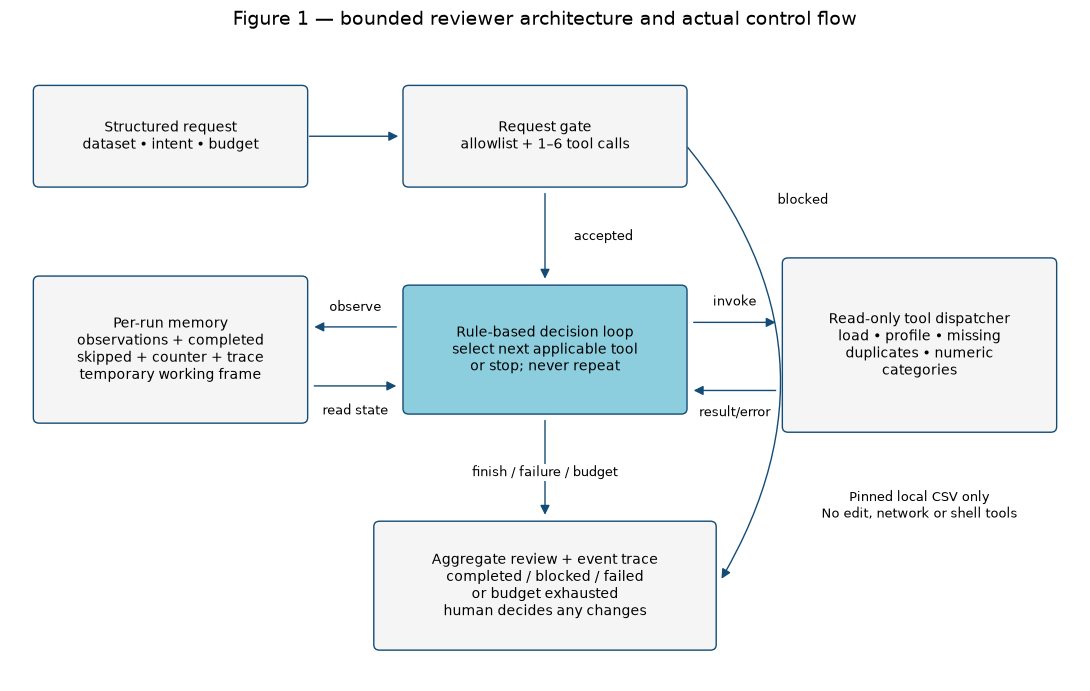

In [2]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.set(xlim=(0, 11), ylim=(0, 7))
ax.axis("off")
boxes = {
    "request": (0.3, 5.5, 2.7, 1.0, "Structured request\ndataset • intent • budget"),
    "guard": (4.1, 5.5, 2.8, 1.0, "Request gate\nallowlist + 1–6 tool calls"),
    "memory": (0.3, 2.9, 2.7, 1.5, "Per-run memory\nobservations + completed\nskipped + counter + trace\ntemporary working frame"),
    "policy": (4.1, 3.0, 2.8, 1.3, "Rule-based decision loop\nselect next applicable tool\nor stop; never repeat"),
    "tools": (8.0, 2.8, 2.7, 1.8, "Read-only tool dispatcher\nload • profile • missing\nduplicates • numeric\ncategories"),
    "result": (3.8, 0.4, 3.4, 1.3, "Aggregate review + event trace\ncompleted / blocked / failed\nor budget exhausted\nhuman decides any changes"),
}
for key, (x, y, w, h, label) in boxes.items():
    patch = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.06",
                           edgecolor="#154C75", facecolor="#8CCEDE" if key == "policy" else "#F5F5F5")
    ax.add_patch(patch)
    ax.text(x+w/2, y+h/2, label, ha="center", va="center", fontsize=10)

def arrow(start, end, label="", label_position=None, curve=0):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14,
                                connectionstyle=f"arc3,rad={curve}", color="#154C75"))
    if label_position:
        ax.text(*label_position, label, fontsize=9, ha="center", va="center",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

arrow((3.05, 6.0), (4.02, 6.0))
arrow((5.5, 5.4), (5.5, 4.4), "accepted", (6.1, 4.9))
arrow((4.0, 3.9), (3.1, 3.9), "observe", (3.55, 4.12))
arrow((3.1, 3.25), (4.0, 3.25), "read state", (3.55, 2.98))
arrow((7.0, 3.95), (7.9, 3.95), "invoke", (7.45, 4.18))
arrow((7.9, 3.2), (7.0, 3.2), "result/error", (7.45, 2.96))
arrow((5.5, 2.9), (5.5, 1.8), "finish / failure / budget", (5.5, 2.3))
arrow((6.95, 5.9), (7.3, 1.1), "blocked", (8.15, 5.3), curve=-0.35)
ax.text(9.35, 1.8, "Pinned local CSV only\nNo edit, network or shell tools",
        ha="center", fontsize=9)
fig.suptitle("Figure 1 — bounded reviewer architecture and actual control flow", fontsize=14)
fig.tight_layout()
fig.savefig(OUT / "architecture_diagram.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Full implementation and decision policy
The source below is the complete implementation supplied as `agentic_system.py`,
not pseudocode. The notebook imports and runs this same module.

Policy order is load → profile → missingness → duplicates → applicable numeric
and category checks → finish. Applicability is decided from observed columns.
Completed-tool state prevents repeats; skips are explicit events. Failure stops
the run, and incomplete checks can never produce `configured_checks_clear`.
Missingness uses `isna()`, rather than equality with NaN (pandas development team,
n.d.). Positive finite numeric rules are deliberately narrow, not biological
plausibility checks.

In [3]:
display(Code(inspect.getsource(agentic_system), language="python"))

"""Bounded, rule-based data-quality reviewer; no LLM, network or data editing."""
from dataclasses import dataclass, field
import hashlib
import io
import json
from pathlib import Path

import numpy as np
import pandas as pd


ROOT = Path(__file__).resolve().parent
CONFIG = json.loads((ROOT / "config.json").read_text())
SOURCE_SHA256 = "f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93"
PERSONA = "Cautious data-quality reviewer: inspect, explain and defer changes to a human."


class ToolFailure(Exception):
    pass


@dataclass(frozen=True)
class Request:
    dataset_id: str = "penguins"
    intent: str = "review"
    max_tool_calls: int = 6


@dataclass
class RunState:
    observations: dict = field(default_factory=dict)
    completed: list = field(default_factory=list)
    skipped: list = field(default_factory=list)
    events: list = field(default_factory=list)
    tool_calls: int = 0
    frame: pd.DataFrame | None = None

    def log(self, action, reason, outcome):
        self.events.append({"sequence": len(self.events) + 1,
                            "action": action, "reason": reason, "outcome": outcome})


class ReviewTools:
    """Read-only functions; fixture input and fault injection are test seams."""

    def __init__(self, fixture=None, fail_tool=None):
        self.fixture = fixture
        self.fail_tool = fail_tool

    def dispatch(self, name, state):
        tools = {"load": self.load, "profile": self.profile,
                 "missing": self.missing, "duplicates": self.duplicates,
                 "numeric": self.numeric, "categories": self.categories}
        if name not in tools:
            raise ToolFailure("Tool is not allowlisted")
        if self.fail_tool == name:
            raise ToolFailure("Injected tool failure for evaluation")
        return tools[name](state)

    def load(self, state):
        if self.fixture is None:
            path = ROOT / CONFIG["relative_path"]
            if path.stat().st_size > CONFIG["max_bytes"]:
                raise ToolFailure("Input exceeds byte limit")
            raw = path.read_bytes()
            if hashlib.sha256(raw).hexdigest() != SOURCE_SHA256:
                raise ToolFailure("Original dataset fingerprint mismatch")
            frame = pd.read_csv(io.BytesIO(raw))
        else:
            frame = self.fixture.copy(deep=True)
        if not 0 < len(frame) <= CONFIG["max_rows"]:
            raise ToolFailure("Input row count is empty or exceeds limit")
        if not 0 < len(frame.columns) <= CONFIG["max_columns"] or not frame.columns.is_unique:
            raise ToolFailure("Invalid column count or repeated column names")
        if not all(isinstance(c, str) and len(c) <= 100 for c in frame.columns):
            raise ToolFailure("Invalid column labels")
        state.frame = frame
        return {"rows": len(frame), "columns": len(frame.columns),
                "source": "explicit evaluation fixture" if self.fixture is not None else "pinned public CSV"}

    def profile(self, state):
        columns = list(state.frame.columns)
        return {"missing_columns": sorted(set(CONFIG["required_columns"]) - set(columns)),
                "extra_column_count": len(set(columns) - set(CONFIG["required_columns"])),
                "measurement_columns": [c for c in CONFIG["measurement_columns"] if c in columns],
                "category_columns": [c for c in CONFIG["categories"] if c in columns]}

    def missing(self, state):
        counts = state.frame.isna().sum()
        return {"missing_cells": int(counts.sum()),
                "rows_with_missing": int(state.frame.isna().any(axis=1).sum()),
                "by_column": {c: int(counts[c]) for c in CONFIG["required_columns"] if c in counts}}

    def duplicates(self, state):
        return {"repeated_rows_after_first": int(state.frame.duplicated().sum())}

    def numeric(self, state):
        counts = {}
        for column in state.observations["profile"]["measurement_columns"]:
     

## 4. Original-data execution and observable decisions
Each trace entry reports a policy action, short reason and observed/requested
outcome. This is an inspectable rule trace, **not an LLM's private reasoning**.
The data remain unchanged. A human-review recommendation never grants the agent
permission to repair a file.

In [4]:
before = hashlib.sha256(source.read_bytes()).hexdigest()
original = ReviewAgent().run(Request())
print("Status:", original["status"])
print("Disposition:", original["disposition"])
print("Findings:", original["findings"])
display(original["observations"])
display(pd.DataFrame(original["trace"]))
assert before == hashlib.sha256(source.read_bytes()).hexdigest()

Status: completed
Disposition: human_review
Findings: ['missing_values']


{'load': {'rows': 344, 'columns': 8, 'source': 'pinned public CSV'},
 'profile': {'missing_columns': [],
  'extra_column_count': 0,
  'measurement_columns': ['bill_length_mm',
   'bill_depth_mm',
   'flipper_length_mm',
   'body_mass_g'],
  'category_columns': ['species', 'island', 'sex']},
 'missing': {'missing_cells': 19,
  'rows_with_missing': 11,
  'by_column': {'species': 0,
   'island': 0,
   'bill_length_mm': 2,
   'bill_depth_mm': 2,
   'flipper_length_mm': 2,
   'body_mass_g': 2,
   'sex': 11,
   'year': 0}},
 'duplicates': {'repeated_rows_after_first': 0},
 'numeric': {'invalid_cells': 0,
  'by_column': {'bill_length_mm': 0,
   'bill_depth_mm': 0,
   'flipper_length_mm': 0,
   'body_mass_g': 0},
  'policy': 'Nonmissing measurement must be numeric, finite and positive; no biological upper bounds.'},
 'categories': {'unexpected_cells': 0,
  'by_column': {'species': 0, 'island': 0, 'sex': 0}}}

,sequence,action,reason,outcome
0,1,load,No dataset is loaded; use the registered read-...,requested
1,2,load,Aggregate observation saved in this run's state.,observed
2,3,profile,Loaded data require a schema observation befor...,requested
3,4,profile,Aggregate observation saved in this run's state.,observed
4,5,missing,Count missing values without deleting or filli...,requested
5,6,missing,Aggregate observation saved in this run's state.,observed
6,7,duplicates,Check repeated attribute rows without assuming...,requested
7,8,duplicates,Aggregate observation saved in this run's state.,observed
8,9,numeric,Profile contains applicable measurement_column...,requested
9,10,numeric,Aggregate observation saved in this run's state.,observed


## 5. Representative scenarios and deliberate failures
The twelve cases were specified in the design plan. Only `original` is
unmodified field data. The harness explicitly constructs complete-case,
duplicate, negative-mass, categories-only, empty, instruction-text and absurd-mass
fixtures from copies; these are **test alterations**, not discovered field
observations. It also submits blocked requests, restricts a call budget and
injects a numeric-tool failure. No fixture preparation is an agent action.

In [5]:
results, evaluation = run_evaluation(OUT / "runs")
display(evaluation)
for name in ["categories_only", "low_budget", "tool_failure", "instruction_text"]:
    result = results[name]
    print("\nSCENARIO:", name, "—", result["status"], "/", result["disposition"])
    display(pd.DataFrame(result["trace"]))
    display(result["observations"])

,scenario,input,status,disposition,tool_calls,findings,expected_behavior_observed
0,original,Original public CSV,completed,human_review,6,missing_values,True
1,complete_cases,Fixture: rows with missing data omitted,completed,configured_checks_clear,6,,True
2,duplicate,Fixture: append one copy of the first row,completed,human_review,6,"missing_values, repeated_rows",True
3,negative_mass,Fixture: first body mass set to -1,completed,human_review,6,"missing_values, invalid_measurements",True
4,categories_only,"Fixture: retain only species, island and sex",completed,human_review,5,"required_columns_missing, missing_values, repe...",True
5,unsupported_dataset,Request an unregistered path,blocked,incomplete_review,0,,True
6,delete_request,Request deletion rather than review,blocked,incomplete_review,0,,True
7,low_budget,Allow only two tool calls,budget_exhausted,incomplete_review,2,,True
8,tool_failure,Inject failure in numeric tool,failed,incomplete_review,5,missing_values,True
9,empty,Fixture: zero rows,failed,incomplete_review,1,,True



SCENARIO: categories_only — completed / human_review


,sequence,action,reason,outcome
0,1,load,No dataset is loaded; use the registered read-...,requested
1,2,load,Aggregate observation saved in this run's state.,observed
2,3,profile,Loaded data require a schema observation befor...,requested
3,4,profile,Aggregate observation saved in this run's state.,observed
4,5,missing,Count missing values without deleting or filli...,requested
5,6,missing,Aggregate observation saved in this run's state.,observed
6,7,duplicates,Check repeated attribute rows without assuming...,requested
7,8,duplicates,Aggregate observation saved in this run's state.,observed
8,9,skip_numeric,No applicable measurement_columns were observed.,skipped
9,10,categories,Profile contains applicable category_columns; ...,requested


{'load': {'rows': 344, 'columns': 3, 'source': 'explicit evaluation fixture'},
 'profile': {'missing_columns': ['bill_depth_mm',
   'bill_length_mm',
   'body_mass_g',
   'flipper_length_mm',
   'year'],
  'extra_column_count': 0,
  'measurement_columns': [],
  'category_columns': ['species', 'island', 'sex']},
 'missing': {'missing_cells': 11,
  'rows_with_missing': 11,
  'by_column': {'species': 0, 'island': 0, 'sex': 11}},
 'duplicates': {'repeated_rows_after_first': 331},
 'categories': {'unexpected_cells': 0,
  'by_column': {'species': 0, 'island': 0, 'sex': 0}}}


SCENARIO: low_budget — budget_exhausted / incomplete_review


,sequence,action,reason,outcome
0,1,load,No dataset is loaded; use the registered read-...,requested
1,2,load,Aggregate observation saved in this run's state.,observed
2,3,profile,Loaded data require a schema observation befor...,requested
3,4,profile,Aggregate observation saved in this run's state.,observed
4,5,finish,Next required tool would exceed the call budget.,budget_exhausted


... (3 outputs left out)

{'load': {'rows': 344, 'columns': 8, 'source': 'pinned public CSV'},
 'profile': {'missing_columns': [],
  'extra_column_count': 0,
  'measurement_columns': ['bill_length_mm',
   'bill_depth_mm',
   'flipper_length_mm',
   'body_mass_g'],
  'category_columns': ['species', 'island', 'sex']},
 'missing': {'missing_cells': 19,
  'rows_with_missing': 11,
  'by_column': {'species': 0,
   'island': 0,
   'bill_length_mm': 2,
   'bill_depth_mm': 2,
   'flipper_length_mm': 2,
   'body_mass_g': 2,
   'sex': 11,
   'year': 0}},
 'duplicates': {'repeated_rows_after_first': 0}}


SCENARIO: instruction_text — completed / human_review


,sequence,action,reason,outcome
0,1,load,No dataset is loaded; use the registered read-...,requested
1,2,load,Aggregate observation saved in this run's state.,observed
2,3,profile,Loaded data require a schema observation befor...,requested
3,4,profile,Aggregate observation saved in this run's state.,observed
4,5,missing,Count missing values without deleting or filli...,requested
5,6,missing,Aggregate observation saved in this run's state.,observed
6,7,duplicates,Check repeated attribute rows without assuming...,requested
7,8,duplicates,Aggregate observation saved in this run's state.,observed
8,9,numeric,Profile contains applicable measurement_column...,requested
9,10,numeric,Aggregate observation saved in this run's state.,observed


{'load': {'rows': 344, 'columns': 8, 'source': 'explicit evaluation fixture'},
 'profile': {'missing_columns': [],
  'extra_column_count': 0,
  'measurement_columns': ['bill_length_mm',
   'bill_depth_mm',
   'flipper_length_mm',
   'body_mass_g'],
  'category_columns': ['species', 'island', 'sex']},
 'missing': {'missing_cells': 19,
  'rows_with_missing': 11,
  'by_column': {'species': 0,
   'island': 0,
   'bill_length_mm': 2,
   'bill_depth_mm': 2,
   'flipper_length_mm': 2,
   'body_mass_g': 2,
   'sex': 11,
   'year': 0}},
 'duplicates': {'repeated_rows_after_first': 0},
 'numeric': {'invalid_cells': 0,
  'by_column': {'bill_length_mm': 0,
   'bill_depth_mm': 0,
   'flipper_length_mm': 0,
   'body_mass_g': 0},
  'policy': 'Nonmissing measurement must be numeric, finite and positive; no biological upper bounds.'},
 'categories': {'unexpected_cells': 1,
  'by_column': {'species': 1, 'island': 0, 'sex': 0}}}

## 6. Evaluation, limitations and responsible use
The original 344-row CSV yields 19 missing cells across 11 records: two in
each of four measurements and eleven in `sex`. Six tool calls complete and
the result is `human_review`; no repeated rows or configured numeric/category
violations are found. Missing cells and affected records are different counts.

The categories-only fixture skips numeric validation based on profile state.
It also shows why repeated attribute rows need interpretation: dropping
measurement columns makes many animals share the same remaining attributes;
this does **not** establish duplicate penguins. The low-budget case stops after
load and profile with `incomplete_review`, not a success claim. Injected numeric
failure stops before category checking; this is a simulated outage, not a
failure of pandas in the original-data run.

The instruction-like species text is never executed or sent to an LLM; it is
counted as an unexpected category. This verifies a narrow data/control separation,
not general prompt-injection resistance. Most importantly, the complete-case
fixture with **999,999 g body mass is not flagged** by positivity-only rules.
The reported `configured_checks_clear` is correct for those rules but would be
misleading if treated as a scientific quality certificate. This known miss is
retained, not relabeled as a robustness success.

All twelve predeclared policy expectations are observed, including that known
miss; this is not 100% anomaly detection, real-world accuracy or comprehensive
safety assurance. Read-only tools, a six-call ceiling, no automatic repairs and
explicit terminal statuses support limited control and accountability, consistent
with risk-management principles rather than certification (NIST, 2023).
The human should investigate missingness rather than silently delete records,
which could alter species, island or sex representation. The notebook uses
public animal data, but aggregate-only logging alone would not establish privacy
for a future sensitive dataset. No OS sandbox, adversarial resource test,
wall-clock timeout or automatic recovery from arbitrary programming bugs is claimed.

## References
Horst, A. M., Hill, A. P., & Gorman, K. B. (2020).
*palmerpenguins: Palmer Archipelago (Antarctica) penguin data* [Data set].
https://doi.org/10.5281/zenodo.3960218

National Institute of Standards and Technology. (2023).
*Artificial intelligence risk management framework (AI RMF 1.0)*
(NIST AI 100-1). https://doi.org/10.6028/NIST.AI.100-1

pandas development team. (n.d.). *Working with missing data*.
https://pandas.pydata.org/docs/user_guide/missing_data.html

Wooldridge, M., & Jennings, N. R. (1995). Intelligent agents: Theory and practice.
*The Knowledge Engineering Review, 10*(2), 115–152.
https://doi.org/10.1017/S0269888900008122

## Notebook summary

This single rule-based agent reviews a registered public penguin dataset with read-only tools, a bounded decision loop and per-run state. On the original data it completes six tool calls and sends missing-value findings for human review without changing a record. Designed evaluation cases exercise conditional tool skipping, duplicate and invalid-value flags, blocked requests, budget exhaustion and a simulated tool failure. A positive but absurd body mass exposes a deliberate limitation of the positivity-only measurement rule rather than demonstrating scientific validation. The workflow has no LLM, general-language planning or persistent memory and cannot certify data quality, infer causality or replace a domain expert.